# Лабораторная работа 4. Нейронные сети для табличных данных
**Вариант 12 (часть B):** Titanic, бинарная классификация `survived`.

План: LightGBM (baseline) → MLP на PyTorch с `nn.Embedding` для категорий → подбор гиперпараметров на валидации →
сравнение на test → PCA / t-SNE / UMAP исходных признаков и скрытого слоя сети.
Разбиение такое же, как в лабах 1–3: test (20%) откладываем сразу. Из train выделяем ещё 20% под валидацию для ранней остановки и подбора.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # чтобы импортировать src/ из notebooks/

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import umap
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.data import CAT_COLS, MODELS_DIR, RANDOM_STATE, ROOT, load_xy
from src.nn import (DEVICE, NUM, cardinalities, fit_mlp, hidden_repr, make_prep,
                    predict_proba, to_tensors)
from src.transformers import add_features
from src.utils import evaluate, tree_pipeline

REPORTS = ROOT / "reports"
print("device:", DEVICE, "| torch", torch.__version__)

E:\adm-labs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | torch 2.15.0+cpu


## 1. Данные и разбиение
train (712) → **tr** (569, обучение) + **val** (143, ранняя остановка и выбор гиперпараметров); **test** (179) только для финальной оценки.
Стратификация везде, `random_state=42`.

In [2]:
X, y = load_xy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                            random_state=RANDOM_STATE)
print({name: len(part) for name, part in [("tr", X_tr), ("val", X_val), ("test", X_test)]})
X.isna().sum()[lambda s: s > 0]

{'tr': 569, 'val': 143, 'test': 179}


age         177
embarked      2
dtype: int64

## 2. Baseline: LightGBM с параметрами по умолчанию
Пайплайн из лабы 3 (`tree_pipeline`): `family_size`, `fare_per_person` → категории в порядковые коды. Пропуски LightGBM обрабатывает сам.
Сначала обучаем на tr и считаем ROC-AUC на val, чтобы сравнить с сетью на одной и той же валидации. Затем обучаем на всём train и оцениваем на test.

In [3]:
lgbm = lambda: tree_pipeline(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1))
lgbm_val_auc = roc_auc_score(y_val, lgbm().fit(X_tr, y_tr).predict_proba(X_val)[:, 1])
lgbm_final = lgbm().fit(X_train, y_train)
lgbm_test = evaluate(lgbm_final, X_test, y_test)
print(f"LightGBM val ROC-AUC: {lgbm_val_auc:.4f}")
lgbm_test

LightGBM val ROC-AUC: 0.8577


{'accuracy': 0.8044692737430168,
 'roc_auc': 0.8252305665349143,
 'pr_auc': 0.7939390746675765,
 'f1': 0.7368421052631579}

## 3. Предобработка для нейросети
По методичке:
- числовые (`age, sibsp, parch, fare` + `family_size, fare_per_person`): медиана → `StandardScaler`. Сети нужен единый масштаб входов, иначе градиенты по `fare` (до 512) забивают остальные признаки;
- категориальные (`pclass, sex, embarked`): мода → **Label Encoding** (`OrdinalEncoder`). Коды не подаются в сеть как числа, они служат индексами строк в таблице `nn.Embedding`. Индекс 0 зарезервирован под категорию, которой не было в train.

Размер эмбеддинга = `min(50, (cardinality + 1) // 2)`. Препроцессор обучается **только на tr**.

In [4]:
prep = make_prep().fit(X_tr)
cards = cardinalities(prep)
tr, val = to_tensors(prep, X_tr, y_tr), to_tensors(prep, X_val, y_val)
pd.DataFrame({"cardinality (+1 unknown)": cards, "emb_dim": [min(50, (c + 1) // 2) for c in cards]}, index=CAT_COLS)

,cardinality (+1 unknown),emb_dim
pclass,4,2
sex,3,2
embarked,4,2


## 4. MLP и подбор гиперпараметров на валидации
Архитектура (`src/nn.py`, `TabularMLP`): `[6 чисел | эмбеддинги pclass, sex, embarked]` → блоки `Linear → BatchNorm → ReLU → Dropout` → `Linear(1)` (логит).
- **BatchNorm** нормирует активации по батчу: обучение идёт стабильнее и меньше зависит от lr;
- **Dropout** на каждом шаге случайно обнуляет часть нейронов. Это регуляризация, она нужна, потому что данных всего 569 строк;
- функция потерь **BCEWithLogitsLoss** (сигмоида + бинарная кросс-энтропия, численно устойчивее, чем отдельная сигмоида), оптимизатор **Adam**, batch 64;
- **ранняя остановка**: максимум 300 эпох, обучение прекращается, если val ROC-AUC не растёт 20 эпох подряд. Берём веса лучшей эпохи.

Сетка: глубина/ширина × dropout × lr = 3 × 2 × 2 = 12 конфигураций.

In [5]:
grid = [dict(hidden=h, dropout=d, lr=lr)
        for h in [(64,), (128, 64), (128, 64, 32)] for d in [0.2, 0.4] for lr in [1e-3, 3e-3]]
rows, runs = [], {}
for i, cfg in enumerate(grid):
    model, hist, best_epoch = fit_mlp(tr, cards, val=val, **cfg)
    runs[i] = hist
    rows.append(cfg | {"best_epoch": best_epoch, "val_auc": max(h["val_auc"] for h in hist)})
search = pd.DataFrame(rows).sort_values("val_auc", ascending=False)
search.round(4)

,hidden,dropout,lr,best_epoch,val_auc
9,"(128, 64, 32)",0.2,0.003,36,0.8964
11,"(128, 64, 32)",0.4,0.003,40,0.8914
8,"(128, 64, 32)",0.2,0.001,48,0.8900
5,"(128, 64)",0.2,0.003,12,0.8852
7,"(128, 64)",0.4,0.003,27,0.8850
4,"(128, 64)",0.2,0.001,6,0.8838
10,"(128, 64, 32)",0.4,0.001,41,0.8821
6,"(128, 64)",0.4,0.001,28,0.8819
1,"(64,)",0.2,0.003,9,0.8741
3,"(64,)",0.4,0.003,9,0.8732


{'hidden': (128, 64, 32), 'dropout': 0.2, 'lr': 0.003} | best epoch: 36


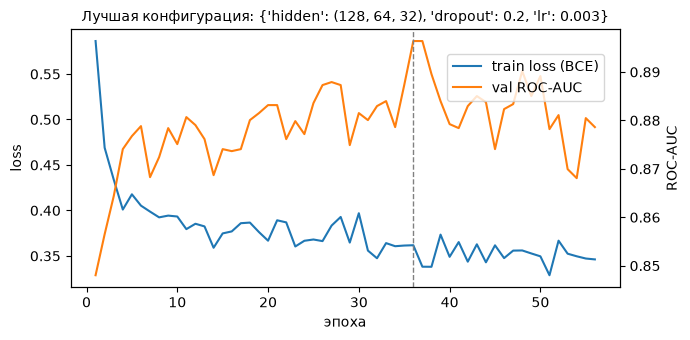

In [6]:
best_id = search.index[0]
best = search.loc[best_id]
best_cfg = dict(hidden=best["hidden"], dropout=float(best["dropout"]), lr=float(best["lr"]))
best_epoch = int(best["best_epoch"])
hist = pd.DataFrame(runs[best_id]).set_index("epoch")

fig, ax = plt.subplots(figsize=(7, 3.5))
hist["train_loss"].plot(ax=ax, label="train loss (BCE)")
ax2 = ax.twinx()
hist["val_auc"].plot(ax=ax2, color="C1", label="val ROC-AUC")
ax2.axvline(best_epoch, color="gray", ls="--", lw=1)
ax.set_xlabel("эпоха"); ax.set_ylabel("loss"); ax2.set_ylabel("ROC-AUC")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.85)); ax.set_title(f"Лучшая конфигурация: {best_cfg}", fontsize=10)
fig.tight_layout(); fig.savefig(REPORTS / "lab4_learning_curve.png", dpi=120, bbox_inches="tight")
print(best_cfg, "| best epoch:", best_epoch)

Разброс val ROC-AUC между конфигурациями нужно сравнивать с шумом самой валидации. На 143 объектах стандартная ошибка ROC-AUC около 0.03,
поэтому почти вся верхняя часть таблицы статистически неразличима. Выбираем лучшую по val, но не переоцениваем этот выбор.

## 5. Финальная сеть и сравнение на test
Лучшую конфигурацию заново обучаем на **всём train** (tr + val, 712 строк) ровно `best_epoch` эпох: валидационная выборка уже выполнила свою роль, а лишние 143 строки для маленького датасета заметны.
Препроцессор тоже обучаем заново, на всём train. Чтобы показать, насколько результат нейросети зависит от инициализации, повторяем финальное обучение с 5 сидами.

In [7]:
prep_full = make_prep().fit(X_train)
train_full = to_tensors(prep_full, X_train, y_train)
x_num_te, x_cat_te = to_tensors(prep_full, X_test)

def mlp_test(seed):
    model, _, _ = fit_mlp(train_full, cardinalities(prep_full), epochs=best_epoch, seed=seed, **best_cfg)
    proba = predict_proba(model, x_num_te, x_cat_te)
    return model, {"accuracy": ((proba >= 0.5) == y_test.values).mean(), "roc_auc": roc_auc_score(y_test, proba)}

mlp, mlp_metrics = mlp_test(RANDOM_STATE)
seed_aucs = [mlp_test(s)[1]["roc_auc"] for s in range(5)]

comparison = pd.DataFrame({
    "LightGBM (default)": {"val ROC-AUC": lgbm_val_auc, "test ROC-AUC": lgbm_test["roc_auc"], "test accuracy": lgbm_test["accuracy"]},
    "MLP + Embedding": {"val ROC-AUC": search["val_auc"].iloc[0], "test ROC-AUC": mlp_metrics["roc_auc"], "test accuracy": mlp_metrics["accuracy"]},
}).T
print(f"MLP test ROC-AUC по 5 сидам: {np.mean(seed_aucs):.4f} ± {np.std(seed_aucs):.4f}")
comparison.round(4)

MLP test ROC-AUC по 5 сидам: 0.8489 ± 0.0073


,val ROC-AUC,test ROC-AUC,test accuracy
LightGBM (default),0.8577,0.8252,0.8045
MLP + Embedding,0.8964,0.8560,0.7933


In [8]:
_ = joblib.dump(lgbm_final, MODELS_DIR / "lab4_lgbm.joblib")
# Для сети сохраняем всё, что нужно для инференса: препроцессор, конфигурацию и веса.
_ = joblib.dump({"prep": prep_full, "cards": cardinalities(prep_full), "config": best_cfg,
             "epochs": best_epoch, "state_dict": mlp.state_dict()}, MODELS_DIR / "lab4_mlp.joblib")

## 6. Снижение размерности: PCA → t-SNE и UMAP
Два представления всех 891 пассажиров:
1. **Исходные признаки после масштабирования**: числа (медиана + StandardScaler) и one-hot категорий, 14 измерений. Здесь one-hot, а не коды: для расстояний между объектами коды 0/1/2 задали бы ложный порядок.
2. **Скрытое представление сети**: выход последнего скрытого слоя обученной MLP.

Схема по методичке: PCA до 50 компонент, затем t-SNE и UMAP. Признаков меньше 50, поэтому PCA сохраняет все компоненты, то есть только поворачивает и центрирует данные (информация не теряется). На графиках PCA показаны первые 2 компоненты.
Все преобразования обучаются на train. Точки train сеть видела при обучении, поэтому их разделение в скрытом слое выглядит оптимистично.

Исходные признаки (scaled + one-hot): 14 изм.
Скрытый слой MLP: 32 изм.


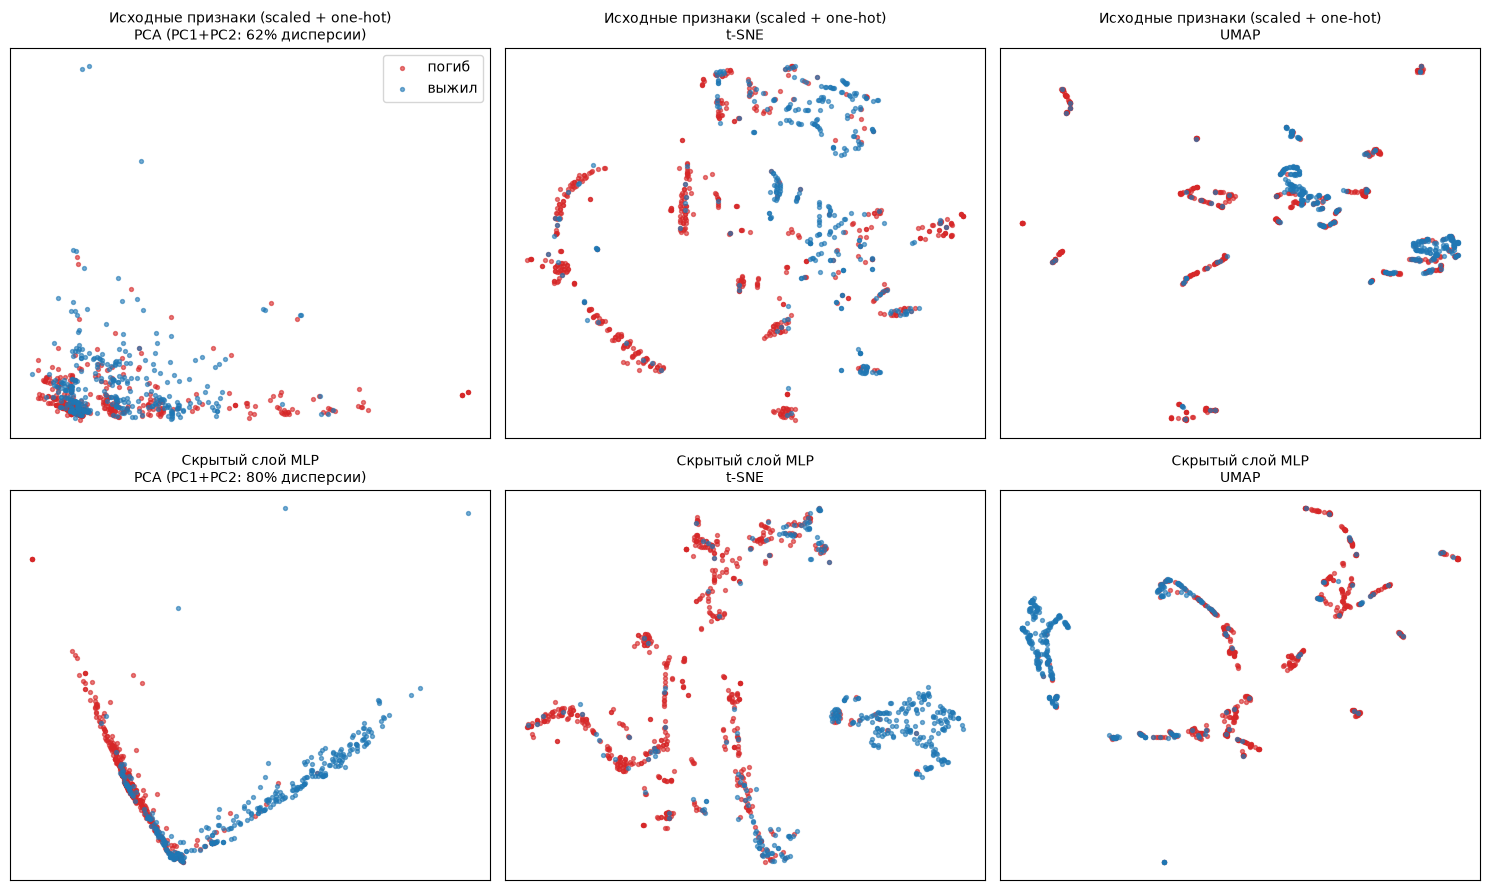

In [9]:
raw_prep = make_pipeline(FunctionTransformer(add_features), ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), CAT_COLS),
])).fit(X_train)
spaces = {"Исходные признаки (scaled + one-hot)": raw_prep.transform(X),
          "Скрытый слой MLP": hidden_repr(mlp, *to_tensors(prep_full, X))}
is_test = X.index.isin(X_test.index)

projections = {}
for name, Z in spaces.items():
    pca = PCA(n_components=min(50, Z.shape[1]), random_state=RANDOM_STATE).fit(Z[~is_test])
    P = pca.transform(Z)
    projections[name] = {
        f"PCA (PC1+PC2: {pca.explained_variance_ratio_[:2].sum():.0%} дисперсии)": P[:, :2],
        "t-SNE": TSNE(perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(P),
        "UMAP": umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE, n_jobs=1,
                          compatibility_layout=True).fit_transform(P),
    }
    print(f"{name}: {Z.shape[1]} изм.")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (name, proj) in zip(axes, projections.items()):
    for ax, (method, E) in zip(row, proj.items()):
        for cls, color, label in [(0, "C3", "погиб"), (1, "C0", "выжил")]:
            m = y.values == cls
            ax.scatter(E[m, 0], E[m, 1], s=8, alpha=0.6, c=color, label=label)
        ax.set_title(f"{name}\n{method}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].legend()
fig.tight_layout(); fig.savefig(REPORTS / "lab4_embeddings.png", dpi=120)

**Линейная разделимость в 2D.** Чтобы оценить разделимость числом, обучаем логистическую регрессию на двух первых компонентах PCA (на train) и считаем ROC-AUC на test.

In [10]:
sep = {}
for name, proj in projections.items():
    P2 = next(iter(proj.values()))  # PCA-2D
    clf = LogisticRegression().fit(P2[~is_test], y[~is_test])
    sep[name] = roc_auc_score(y[is_test], clf.predict_proba(P2[is_test])[:, 1])
pd.Series(sep, name="test ROC-AUC LogReg на PC1+PC2").round(4)

Исходные признаки (scaled + one-hot)    0.6781
Скрытый слой MLP                        0.8574
Name: test ROC-AUC LogReg на PC1+PC2, dtype: float64

## 7. Выводы
| | val ROC-AUC | test ROC-AUC | test accuracy |
|---|---|---|---|
| LightGBM (default) | 0.858 | 0.825 | 0.804 |
| MLP + Embedding `(128, 64, 32)`, dropout 0.2, lr 3e-3, 36 эпох | 0.896 | **0.856** (0.849 ± 0.007 по 5 сидам) | 0.793 |

**Модели**
- MLP обошла LightGBM с параметрами по умолчанию на test на 0.03 ROC-AUC. Дефолтный LightGBM (31 лист, 100 деревьев) слишком сложен для 712 строк и переобучается. Настроенный в лабе 3 LightGBM (неглубокие деревья, маленький шаг) давал на CV 0.890. Поэтому вывод «нейросеть лучше бустинга» делать нельзя: сеть не хуже бустинга без настройки.
- Val ROC-AUC сети (0.896) завышен. Это максимум по 12 конфигурациям, и эпоха тоже выбрана по той же валидации, то есть мы подстроились под шум 143 объектов. Честная оценка — test (0.856).
- Разница между верхними конфигурациями (≈0.005–0.01) меньше стандартной ошибки на валидации (≈0.03). Устойчиво видно только одно: однослойные сети стабильно хуже трёхслойных. Ранняя остановка срабатывает на 10–50-й эпохе: на маленьком датасете сеть быстро начинает переобучаться.
- Результат сети зависит от инициализации (±0.007 по сидам), у LightGBM такой зависимости нет. Это обычная цена нейросетей, поэтому о ней стоит сообщать вместе с метрикой.
- По ROC-AUC сеть лучше, а по accuracy немного хуже. ROC-AUC оценивает ранжирование по всем порогам, а accuracy — только порог 0.5.
- Эмбеддинги здесь нужны скорее методически: у `pclass/sex/embarked` всего 2–3 значения, и эмбеддинг размерности 2 почти эквивалентен one-hot. Выигрыш от `nn.Embedding` проявляется на признаках с сотнями и тысячами категорий (город, товар, пользователь).
- Общий итог лаб 1–4: на маленьком табличном датасете с сильным сигналом в 2–3 признаках сложные модели не дают устойчивого выигрыша над логистической регрессией (test 0.864 в лабе 2). Все различия укладываются в 95% интервал ROC-AUC на 179 объектах (±0.07).

**Визуализация**
- *Исходные признаки, PCA:* первые две компоненты объясняют 62% дисперсии, но классы на них почти не разделяются (LogReg на PC1+PC2: test ROC-AUC 0.678). PCA ищет направления максимальной **дисперсии** (`fare`, размер семьи), а не направления, по которым различаются классы. Самый сильный признак `sex` бинарный, и его дисперсия невелика.
- *Исходные признаки, t-SNE/UMAP:* много мелких плотных кластеров. Признаки дискретные, поэтому пассажиры с одинаковыми полом, классом, портом и семьёй почти совпадают. Многие кластеры заметно однородны по цвету, то есть локальная структура связана с выживанием, но глобально классы перемешаны.
- *Скрытый слой сети:* PCA даёт V-образную структуру, две ветки — «погиб» и «выжил», и первые две компоненты объясняют 80% дисперсии. LogReg на PC1+PC2 даёт 0.857, то есть столько же, сколько вся модель. Сеть сжала 32-мерное представление почти в одномерную «шкалу выживания». На одном конце этой шкалы женщины 1–2 класса (выживаемость 92–97%), на другом мужчины 2–3 класса (14–16%). В середине, где цвета смешаны, находятся женщины 3-го класса (50%) и мужчины 1-го класса (37%): именно на них модель ошибается.
- t-SNE и UMAP скрытого слоя показывают то же самое: отдельный крупный «синий» кластер и «красные» тяжи. Скрытое представление разделимо гораздо лучше исходного, потому что сеть обучалась именно разделять классы (для точек train картинка ещё и оптимистична).
- t-SNE и UMAP сохраняют в первую очередь локальную структуру (соседей). Поэтому расстояния между кластерами и их размеры на этих картинках интерпретировать нельзя, в отличие от PCA.